# DemandIQ — Exploration

Initial notebook for exploring source files in `data/raw/`.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "../data/raw/train.csv",
    parse_dates=["date"]
)

df.head()


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


In [4]:
print("Shape:", df.shape)
print("Data types:\n", df.dtypes)
print("Earliest date:", df["date"].min())
print("Latest date:", df["date"].max())
print("Unique stores:", df["store_nbr"].nunique())
print("Unique product families:", df["family"].nunique())


Shape: (3000888, 6)
Data types:
 id                      int64
date           datetime64[us]
store_nbr               int64
family                    str
sales                 float64
onpromotion             int64
dtype: object
Earliest date: 2013-01-01 00:00:00
Latest date: 2017-08-15 00:00:00
Unique stores: 54
Unique product families: 33


In [6]:
print(df.isna().sum())
print(df.duplicated(subset=["date", "store_nbr", "family"]).sum())
print(df.describe())
    

id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64
0
                 id                        date     store_nbr         sales  \
count  3.000888e+06                     3000888  3.000888e+06  3.000888e+06   
mean   1.500444e+06  2015-04-24 08:27:04.703088  2.750000e+01  3.577757e+02   
min    0.000000e+00         2013-01-01 00:00:00  1.000000e+00  0.000000e+00   
25%    7.502218e+05         2014-02-26 18:00:00  1.400000e+01  0.000000e+00   
50%    1.500444e+06         2015-04-24 12:00:00  2.750000e+01  1.100000e+01   
75%    2.250665e+06         2016-06-19 06:00:00  4.100000e+01  1.958473e+02   
max    3.000887e+06         2017-08-15 00:00:00  5.400000e+01  1.247170e+05   
std    8.662819e+05                         NaN  1.558579e+01  1.101998e+03   

        onpromotion  
count  3.000888e+06  
mean   2.602770e+00  
min    0.000000e+00  
25%    0.000000e+00  
50%    0.000000e+00  
75%    0.000000e+00  
max    7.410000e+

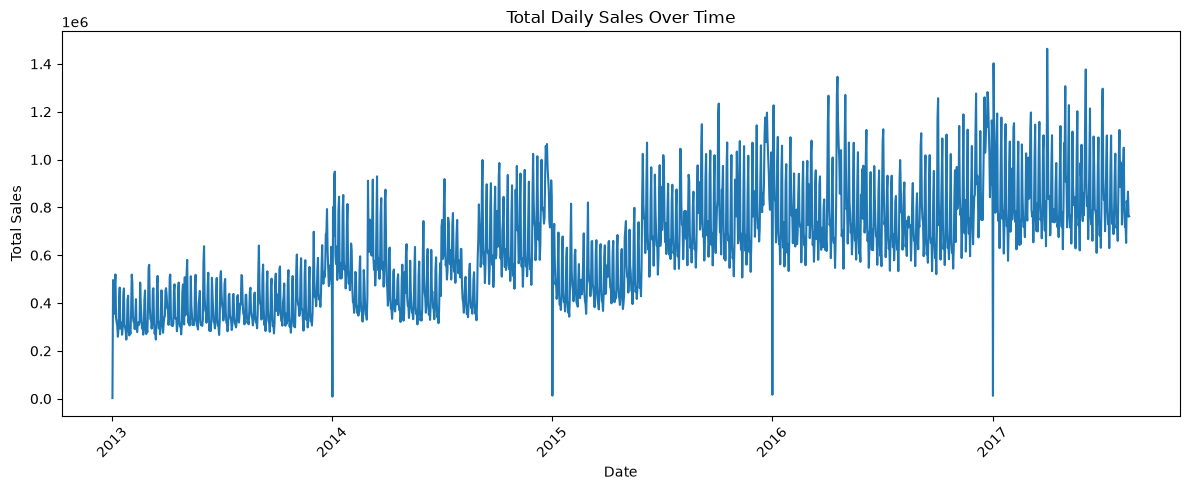

In [8]:
daily_sales = (
    df.groupby("date")["sales"]
      .sum()
      .sort_index()
)

plt.figure(figsize=(12, 5))

plt.plot(
    daily_sales.index,
    daily_sales.values
)

plt.title("Total Daily Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()